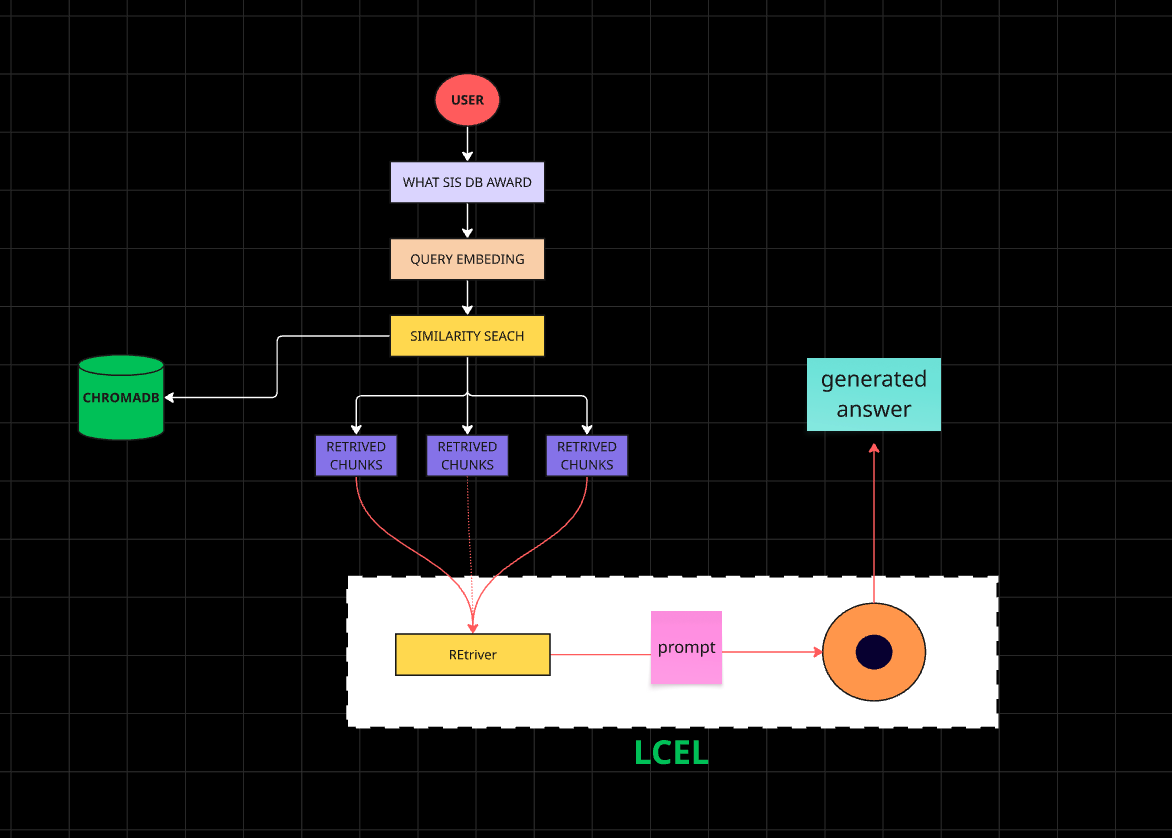

In [2]:
# Libraries import
import os 
from dotenv import load_dotenv
load_dotenv(override=True)

## text loading # directory load #embediings # text splitting
from langchain_community.document_loaders import DirectoryLoader, TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_openai import OpenAIEmbeddings

from langchain_openai import ChatOpenAI

# vector store
from langchain_community.vectorstores import FAISS

#prompt template and LCEL
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_47790/3636336566.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import DirectoryLoader, TextLoader
/Volumes/ManojData/github/ITK-FREE-GENAI-SERIES-NOTES/.ITK-FREE-GENAI-SERIES-NOTES/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# TO ENABLE MONITORING THE AI WORKLOADS WILL BE USING https://smith.langchain.com/
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGCHAIN_ENDPOINT"] = "https://api.smith.langchain.com"
os.environ["LANGCHAIN_PROJECT"] = os.getenv("LANGSMITH_PROJECT", "ITK-GENAI")

In [5]:
langsmith_key = os.getenv("LANGSMITH_API_KEY")
if langsmith_key:
    os.environ["LANGCHAIN_API_KEY"] = langsmith_key

In [6]:
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [7]:
# Loding steps:
from docx import document


dir_loader = DirectoryLoader(
    "data",
    glob = "*.txt", # pattern that matches the files
    loader_cls=TextLoader,
    loader_kwargs={
        'encoding':'utf-8'
    },
)

documents = dir_loader.load()
print(f"Total document loaded: {len(documents)}")
documents[0]

Total document loaded: 4


Document(metadata={'source': 'data/python.txt'}, page_content='Python is a high-level, interpreted, \ngeneral-purpose programming language known for its simple syntax and readability. \nIt is widely used in software development, automation, data science, artificial intelligence, \nmachine learning, web development, and DevOps. Python provides many built-in libraries and has a large ecosystem of third-party packages. Frameworks such as FastAPI, Flask, and Django help developers build web applications and APIs. Python is also popular in automation because developers can easily write scripts for managing infrastructure, processing files, interacting with APIs, and performing repetitive tasks. Its simplicity and versatility make Python one of the most widely used programming languages in modern technology.')

In [8]:
# Stage 2: Document Splitting

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size = 500,
    chunk_overlap = 50,
    length_function = len,
    separators= [" "]
)

chunks = text_splitter.split_documents(documents)
print(f"created {len(chunks)} chunks from {len(documents)} documents")

created 108 chunks from 4 documents


In [9]:
print("content: ")
print(chunks[0].page_content)

print("Metadata: ")
print(chunks[0].metadata)

content: 
Python is a high-level, interpreted, 
general-purpose programming language known for its simple syntax and readability. 
It is widely used in software development, automation, data science, artificial intelligence, 
machine learning, web development, and DevOps. Python provides many built-in libraries and has a large ecosystem of third-party packages. Frameworks such as FastAPI, Flask, and Django help developers build web applications and APIs. Python is also popular in automation because
Metadata: 
{'source': 'data/python.txt'}


In [10]:
# stage-3 embeddings
embeddings = OpenAIEmbeddings(
    model = "text-embedding-3-small"
)

FAISS provided by FACEBOOK

Introduction to RAG (Retrieval-Augmented Generation) RAG combines the power of retrieval systems with generative AI models. Instead of relying solely on the model's training data, RAG:

Retrieves relevant documents from a knowledge base
Uses these documents as context for the LLM
Generates responses based on both the retrieved context and the model's knowledge
FAISS
https://github.com/facebookresearch/faiss

FAISS is a library for efficient similarity search and clustering of dense vectors.

Key advantages:

- Extremely fast similarity search
- Memory efficient
- Supports GPU acceleration
- Can handle millions of vectors
- How it works:

Indexes vectors for fast nearest neighbor search
Returns most similar vectors based on distance metrics

In [15]:
vector_store = FAISS.from_documents(
    documents=chunks,
    embedding=embeddings,
)

In [16]:
vector_store.save_local("faiss_index")

In [17]:
query = "What is the Dadasaheb Phalke Award?"

similar_docs = vector_store.similarity_search(
    query,
    k=3
)

similar_docs

[Document(id='e91a44cf-dcfe-43e8-af19-c80a587af0df', metadata={'source': 'data/award.txt'}, page_content="for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.\n\n## What is the Dadasaheb Phalke Award?\n\nThe Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913.\n\nThe award recognizes outstanding"),
 Document(id='4852c66c-6124-4855-b4da-86bb0e271086', metadata={'source': 'data/award.txt'}, page_content="of Indian cinema.\n\nAnant Nag has been a part of that landscape for more than five decades.\n\n## Conclusion\n\nThe Dadasaheb Phalke Award is one of the most significant recognitions an Indian film artist can receive. In 2026, this honour was presented to Anant Nag for his outstanding cont

In [18]:
similar_docs[0].page_content

"for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.\n\n## What is the Dadasaheb Phalke Award?\n\nThe Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913.\n\nThe award recognizes outstanding"

In [20]:
query = "What is the Dadasaheb Phalke Award?"

result_score=vector_store.similarity_search_with_score(
    query,
    k=3
)

result_score

[(Document(id='e91a44cf-dcfe-43e8-af19-c80a587af0df', metadata={'source': 'data/award.txt'}, page_content="for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.\n\n## What is the Dadasaheb Phalke Award?\n\nThe Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913.\n\nThe award recognizes outstanding"),
  np.float32(0.46111944)),
 (Document(id='4852c66c-6124-4855-b4da-86bb0e271086', metadata={'source': 'data/award.txt'}, page_content="of Indian cinema.\n\nAnant Nag has been a part of that landscape for more than five decades.\n\n## Conclusion\n\nThe Dadasaheb Phalke Award is one of the most significant recognitions an Indian film artist can receive. In 2026, this honour was presented to Anant

In [21]:
print(result_score)

[(Document(id='e91a44cf-dcfe-43e8-af19-c80a587af0df', metadata={'source': 'data/award.txt'}, page_content="for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.\n\n## What is the Dadasaheb Phalke Award?\n\nThe Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913.\n\nThe award recognizes outstanding"), np.float32(0.46111944)), (Document(id='4852c66c-6124-4855-b4da-86bb0e271086', metadata={'source': 'data/award.txt'}, page_content="of Indian cinema.\n\nAnant Nag has been a part of that landscape for more than five decades.\n\n## Conclusion\n\nThe Dadasaheb Phalke Award is one of the most significant recognitions an Indian film artist can receive. In 2026, this honour was presented to Anant Na

In [22]:
for doc,score in result_score:
    print("\nScore:", score)
    print(doc.page_content[:300]) 


Score: 0.46111944
for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.

## What is the Dadasaheb Phalke Award?

The Dadasaheb Phalke Award was institu

Score: 0.87363994
of Indian cinema.

Anant Nag has been a part of that landscape for more than five decades.

## Conclusion

The Dadasaheb Phalke Award is one of the most significant recognitions an Indian film artist can receive. In 2026, this honour was presented to Anant Nag for his outstanding contribution to Ind

Score: 0.8804796
# Anant Nag and the Dadasaheb Phalke Award: A Golden Recognition for Kannada Cinema

Indian cinema is not just about entertainment. It is a reflection of our culture, language, emotions, traditions and society. Over the decades, many artists have dedicated their lives to enriching Indian cinema. Amo


In [23]:
#stage-6 creating retriver
retriever = vector_store.as_retriever(
    search_kwargs={
        "k": 3
    }
)

In [24]:
retriever

VectorStoreRetriever(tags=['FAISS', 'OpenAIEmbeddings'], vectorstore=<langchain_community.vectorstores.faiss.FAISS object at 0x131ecee70>, search_kwargs={'k': 3})

In [25]:
query = "What is the Dadasaheb Phalke Award?"
retrived_docs = retriever.invoke(query)
retrived_docs

[Document(id='e91a44cf-dcfe-43e8-af19-c80a587af0df', metadata={'source': 'data/award.txt'}, page_content="for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.\n\n## What is the Dadasaheb Phalke Award?\n\nThe Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913.\n\nThe award recognizes outstanding"),
 Document(id='4852c66c-6124-4855-b4da-86bb0e271086', metadata={'source': 'data/award.txt'}, page_content="of Indian cinema.\n\nAnant Nag has been a part of that landscape for more than five decades.\n\n## Conclusion\n\nThe Dadasaheb Phalke Award is one of the most significant recognitions an Indian film artist can receive. In 2026, this honour was presented to Anant Nag for his outstanding cont

In [26]:
for i, doc in enumerate(retrived_docs, start=1):
    print(f"\n--- Retrieved Document {i} ---")
    print(doc.page_content)
    print("Metadata:", doc.metadata)


--- Retrieved Document 1 ---
for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.

## What is the Dadasaheb Phalke Award?

The Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913.

The award recognizes outstanding
Metadata: {'source': 'data/award.txt'}

--- Retrieved Document 2 ---
of Indian cinema.

Anant Nag has been a part of that landscape for more than five decades.

## Conclusion

The Dadasaheb Phalke Award is one of the most significant recognitions an Indian film artist can receive. In 2026, this honour was presented to Anant Nag for his outstanding contribution to Indian cinema.

For Karnataka, Kannada cinema and millions of his admirers, this is a memorable moment.

From theatr

In [28]:
llm = ChatOpenAI(
    model = 'gpt-4o-mini',
    temperature=0
)

In [31]:

response = llm.invoke("hi")

In [32]:
response.content

'Hello! How can I assist you today?'

In [33]:
#STAGE-8 CREATING THE RAG TEMPLATE
custom_prompt = ChatPromptTemplate.from_template("""
You are a helpful assistant.

Answer the question using ONLY the provided context.

If the answer cannot be found in the context, say:
"I don't know based on the provided documents."

Context:
{context}

Question:
{question}

Answer:
""")

In [34]:
# STAGE-9 BUILDING COMPLETE RAG

ragchain = (
    {
        "context": retriever,
        "question": RunnablePassthrough()
    }
    | custom_prompt
    | llm
    | StrOutputParser()
)

In [35]:
# TESTING PHASE:
question = "What is the Dadasaheb Phalke Award?"

answer = ragchain.invoke(question)

print(answer)

The Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913. The award recognizes outstanding contributions to Indian cinema.


In [36]:
question = "can you sing song for me becuse its 1:00AM"

answer = ragchain.invoke(question)

print(answer)

I don't know based on the provided documents.
